# Main-paper figures and timings

Note: the copula calculation is comparatively slow. Figures are saved in `plots/simulation/`.


In [1]:
# Locate code_rm whether the notebook is launched from its folder or the root.
from pathlib import Path
import os
import sys
ROOT = Path.cwd().resolve()
if ROOT.name == "simulation":
    ROOT = ROOT.parent
if not (ROOT / "recursive_moments").is_dir():
    raise RuntimeError("Launch this notebook from code_rm or code_rm/simulation.")
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
(ROOT / "plots" / "simulation").mkdir(parents=True, exist_ok=True)


In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import jax.numpy as jnp

# Gaussian Example 2.2 (Fig 1)

In [4]:
import time
import numpy as np
import jax.numpy as jnp
import matplotlib.pyplot as plt

from recursive_moments import RMGauss, RMSU, RMCopula


# ============================================================
# SETTINGS
# ============================================================

setting = "het"
seed = 125
n = 200
n_perm_opt = 10

# Choose exactly two:
methods = ("cop", "gauss")

T_pr = 4000
pr_seed = 126

# Copula PR is considerably more expensive.
B_by_method = {
    "cop": 1000,
    "gauss": 1000,
    "su": 1000,
}

# Optional axis limits
y_range = None
variance_range = None


# ============================================================
# METHOD REGISTRY
# ============================================================

METHODS = {
    "cop": {
        "class": RMCopula,
        "label": "Copula",
        "color": "royalblue",
    },
    "gauss": {
        "class": RMGauss,
        "label": "Gauss",
        "color": "darkorange",
    },
    "su": {
        "class": RMSU,
        "label": "SU",
        "color": "darkblue",
    },
}

ALIASES = {
    "copula": "cop",
    "rmcopula": "cop",
    "rmgauss": "gauss",
    "rmsu": "su",
}


def normalize_method(name):
    name = name.lower().replace("-", "_")
    name = ALIASES.get(name, name)

    if name not in METHODS:
        raise ValueError(
            f"Unknown method {name!r}. "
            f"Choose from {list(METHODS)}."
        )

    return name


methods = tuple(normalize_method(name) for name in methods)

if len(methods) != 2 or methods[0] == methods[1]:
    raise ValueError("Specify two distinct methods.")


# ============================================================
# LOAD SIMULATION DATA
# ============================================================

data_dir = "data/simulation"


def load_sim(name, seed_specific=False):
    suffix = f"_seed{seed}_n{n}" if seed_specific else ""
    path = f"{data_dir}/sim_{setting}_{name}{suffix}.csv"
    return np.loadtxt(path, delimiter=",")


seed_files = ["X", "y", "X_test", "y_test", "y_grid"]
truth_files = [
    "x_grid",
    "mean_truth",
    "var_truth",
    "y_l_truth",
    "y_h_truth",
]

D = {name: load_sim(name, True) for name in seed_files}
T = {name: load_sim(name, False) for name in truth_files}

X = D["X"].reshape(-1, 1)
y = D["y"]
X_test = D["X_test"].reshape(-1, 1)
y_test = D["y_test"]
y_plot = jnp.asarray(D["y_grid"])

x_plot = jnp.asarray(T["x_grid"].reshape(-1, 1))
mean_truth = np.asarray(T["mean_truth"])
var_truth = np.asarray(T["var_truth"])

if setting in {"het", "kurt"}:
    X_range = (-7.0, 7.0)
else:
    raise ValueError(f"Unsupported univariate setting: {setting!r}")


# ============================================================
# FIT AND PREDICT
# ============================================================

def run_method(method):
    specification = METHODS[method]

    model = specification["class"](
        optimize=True,
        n_perm_opt=n_perm_opt,
        n_perm_fit=10,
    )

    start = time.perf_counter()
    model.fit(X, y)
    fit_seconds = time.perf_counter() - start

    start = time.perf_counter()

    if method == "cop":
        prediction = model.predict(
            x_plot,
            y_grid=y_plot,
            return_summaries=True,
        )

        _, moments = model.pr(
            X_test=x_plot,
            y_grid=y_plot,
            T=T_pr,
            B=B_by_method[method],
            seed=pr_seed,
            return_intervals=True,
            X_range=X_range,
        )
    else:
        prediction = model.predict(x_plot)

        _, moments = model.pr(
            X_test=x_plot,
            T=T_pr,
            B=B_by_method[method],
            seed=pr_seed,
            return_intervals=True,
            X_range=X_range,
        )

    # Force JAX calculations to finish before reporting the time.
    np.asarray(moments["μ_mean"])
    prediction_seconds = time.perf_counter() - start

    print(
        f"{specification['label']}: "
        f"fit = {fit_seconds:.2f}s, "
        f"prediction/PR = {prediction_seconds:.2f}s"
    )
    print(f"  rho_x = {model.rho_x_}")
    print(f"  rho_y = {model.rho_y_}")
    print(f"  prequential log likelihood = {model.preq_loglik_}")

    return {
        "model": model,
        "prediction": prediction,
        "moments": moments,
    }


results = {
    method: run_method(method)
    for method in methods
}

Bandwidth optimization success: True
Copula: fit = 2.18s, prediction/PR = 196.69s
  rho_x = [0.92280287]
  rho_y = 0.750449538230896
  prequential log likelihood = -0.8462638854980469
Bandwidth optimization success: True
Gauss: fit = 0.51s, prediction/PR = 0.46s
  rho_x = [0.91699976]
  rho_y = 0.8682929873466492
  prequential log likelihood = -0.8426665663719177


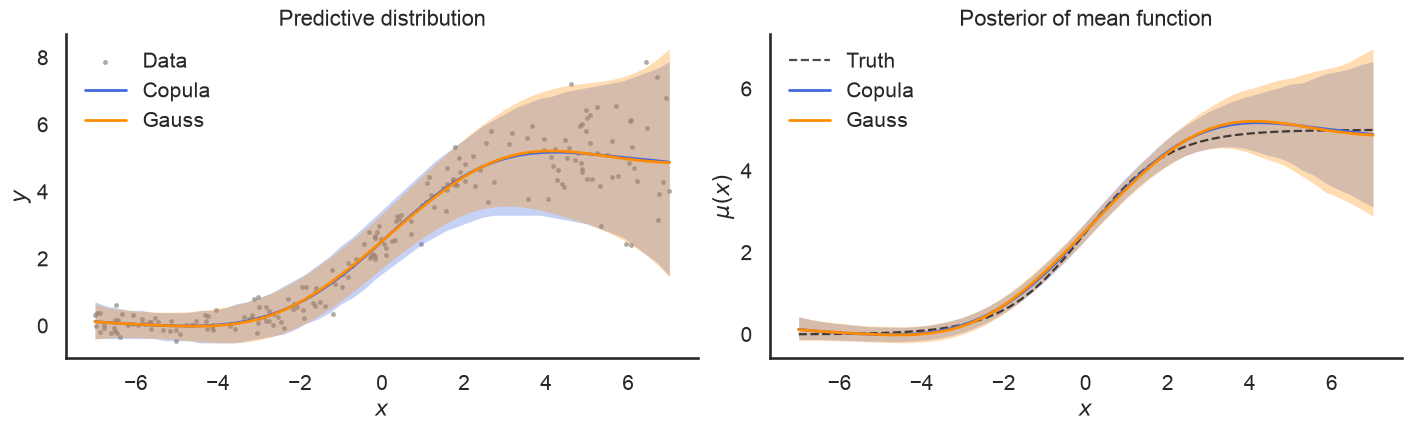

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


METHODS = {
    "cop": {
        "class": RMCopula,
        "label": "Copula",
        "color": "royalblue",
    },
    "gauss": {
        "class": RMGauss,
        "label": "Gauss",
        "color": "darkorange",
    },
    "su": {
        "class": RMSU,
        "label": "SU",
        "color": "darkorange",
    },
}


# ============================================================
# SEABORN STYLE
# ============================================================

sns.set_theme(
    style="white",
    context="talk",
    font_scale=0.9,
)


# ============================================================
# TWO-PANEL PLOT
# ============================================================

x_grid = np.asarray(x_plot[:, 0])
order = np.argsort(x_grid)

x_grid = x_grid[order]
mean_truth_plot = np.asarray(mean_truth)[order]
var_truth_plot = np.asarray(var_truth)[order]


fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 4.2),
    constrained_layout=True,
)


# ============================================================
# Panel 1: data and predictive intervals
# ============================================================

sns.scatterplot(
    x=X[:, 0],
    y=y,
    s=10,
    color="gray",
    alpha=0.65,
    edgecolor=None,
    label="Data",
    ax=axes[0],
    zorder=1,
)


for method in methods:
    specification = METHODS[method]
    prediction = results[method]["prediction"]

    predictive_mean = np.asarray(prediction["μ"])[order]
    predictive_lower = np.asarray(prediction["y_l"])[order]
    predictive_upper = np.asarray(prediction["y_h"])[order]

    sns.lineplot(
        x=x_grid,
        y=predictive_mean,
        color=specification["color"],
        linewidth=2,
        label=specification["label"],
        ax=axes[0],
        zorder=3,
    )

    axes[0].fill_between(
        x_grid,
        predictive_lower,
        predictive_upper,
        color=specification["color"],
        alpha=0.30,
        linewidth=0,
        zorder=2,
    )


axes[0].set(
    title="Predictive distribution",
    xlabel=r"$x$",
    ylabel=r"$y$",
)

if y_range is not None:
    axes[0].set_ylim(y_range)

axes[0].legend(frameon=False)


# ============================================================
# Panel 2: posterior mean function
# ============================================================

sns.lineplot(
    x=x_grid,
    y=mean_truth_plot,
    linestyle="--",
    color="black",
    linewidth=1.6,
    alpha=0.7,
    label="Truth",
    ax=axes[1],
)


for method in methods:
    specification = METHODS[method]
    moments = results[method]["moments"]

    posterior_mean = np.asarray(moments["μ_mean"])[order]
    credible_lower = np.asarray(moments["μ_l"])[order]
    credible_upper = np.asarray(moments["μ_h"])[order]

    sns.lineplot(
        x=x_grid,
        y=posterior_mean,
        color=specification["color"],
        linewidth=2,
        label=specification["label"],
        ax=axes[1],
    )

    axes[1].fill_between(
        x_grid,
        credible_lower,
        credible_upper,
        color=specification["color"],
        alpha=0.30,
        linewidth=0,
    )


axes[1].set(
    title="Posterior of mean function",
    xlabel=r"$x$",
    ylabel=r"$\mu(x)$",
)

if y_range is not None:
    axes[1].set_ylim(y_range)

axes[1].legend(frameon=False)


# ============================================================
# Final styling
# ============================================================

sns.despine(fig=fig)



plt.savefig(
    "./plots/simulation/het_sim.pdf",
    bbox_inches="tight",
)

plt.show()

# SU Mean Update (Figure 2)

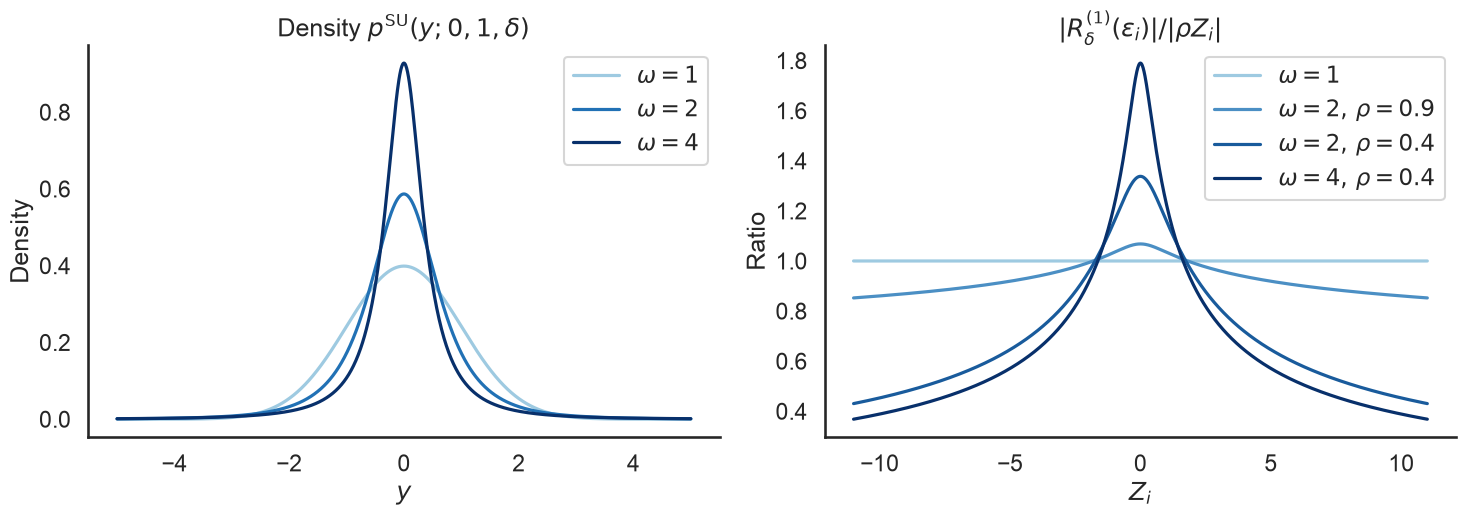

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import norm
from matplotlib.colors import LinearSegmentedColormap


# ============================================================
# Settings
# ============================================================

# Left panel: different values of omega
omega_values = [1.0, 2.0, 4.0]

# Right panel: selected (omega, rho) pairs
ratio_settings = [
    (1.0,0.9),
    (2.0, 0.9),
    (2.0, 0.4),
    (4.0, 0.4),
]

y_grid = np.linspace(-5.0, 5.0, 1200)
eps_grid = np.linspace(-11.0, 11.0, 1200)


# ============================================================
# Symmetric Johnson SU utilities
# ============================================================

def su_delta_from_omega(omega):
    """
    delta = 1 / sqrt(log omega).

    Only used for omega > 1.
    The limiting case omega = 1 is Gaussian.
    """
    if omega <= 1.0:
        raise ValueError("su_delta_from_omega requires omega > 1.")
    return 1.0 / np.sqrt(np.log(omega))


def su_D(omega):
    """
    D_delta = sqrt{ (omega - 1)(omega + 1) / 2 }
            = sqrt{ (omega^2 - 1) / 2 }.
    """
    return np.sqrt(0.5 * (omega**2 - 1.0))


def su_pdf(y, omega):
    """
    Density of the standardized symmetric SU family

        Y = sinh(Z / delta) / D_delta,

    where

        omega = exp(1 / delta^2),
        D_delta^2 = (omega^2 - 1) / 2.

    The omega = 1 limiting case is N(0,1).
    """
    if np.isclose(omega, 1.0):
        return norm.pdf(y)

    delta = su_delta_from_omega(omega)
    D = su_D(omega)

    z = delta * np.arcsinh(D * y)
    jac = delta * D / np.sqrt(1.0 + (D * y)**2)

    return norm.pdf(z) * jac


def su_R1_from_eps(eps, omega, rho):
    r"""
    R_delta^{(1)}(Z_i) as a function of epsilon_i.

    Since

        Z_i = delta * asinh(D_delta * epsilon_i),

    we have

        R_delta^{(1)}(Z_i)
        =
        omega^((1-rho^2)/2)
        sinh(rho * Z_i / delta)
        / D_delta

        =
        omega^((1-rho^2)/2)
        sinh(rho * asinh(D_delta * epsilon_i))
        / D_delta.

    The omega = 1 limiting case is rho * epsilon_i.
    """
    if np.isclose(omega, 1.0):
        return rho * eps

    D = su_D(omega)

    return (
        omega ** ((1.0 - rho**2) / 2.0)
        * np.sinh(rho * np.arcsinh(D * eps))
        / D
    )


# ============================================================
# Build plotting data
# ============================================================

dens_rows = []
ratio_rows = []

# ------------------------------------------------------------
# Left panel data
# ------------------------------------------------------------

for omega in omega_values:
    dens = su_pdf(y_grid, omega)

    for yy, dd in zip(y_grid, dens):
        dens_rows.append(
            {
                "y": yy,
                "density": dd,
                "omega": omega,
            }
        )


# ------------------------------------------------------------
# Right panel data
# ------------------------------------------------------------

for omega, rho in ratio_settings:
    r1 = su_R1_from_eps(eps_grid, omega, rho)

    denom = rho * eps_grid

    # Absolute ratio:
    # |R_delta^{(1)}(Z_i)| / |rho epsilon_i|
    ratio = np.full_like(eps_grid, np.nan, dtype=float)
    mask = np.abs(denom) > 1e-12
    ratio[mask] = np.abs(r1[mask]) / np.abs(denom[mask])

    setting = rf"$\omega={omega:g},\,\rho={rho:g}$"

    for ee, rr in zip(eps_grid, ratio):
        ratio_rows.append(
            {
                "epsilon": ee,
                "R1_ratio": rr,
                "setting": setting,
            }
        )


df_dens = pd.DataFrame(dens_rows)
df_ratio = pd.DataFrame(ratio_rows)


# ============================================================
# Plot
# ============================================================

sns.set_theme(style="white", context="talk")

cmap = LinearSegmentedColormap.from_list(
    "lightblue_blue_black",
    ["#9ecae1", "#2171b5", "#08306b"],
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))


# ============================================================
# Left: SU densities for different omega
# ============================================================

unique_omegas = sorted(omega_values)

omega_colors = [
    cmap(i / (len(unique_omegas) - 1))
    for i in range(len(unique_omegas))
]

omega_palette = dict(zip(unique_omegas, omega_colors))

sns.lineplot(
    data=df_dens,
    x="y",
    y="density",
    hue="omega",
    hue_order=unique_omegas,
    palette=omega_palette,
    ax=axes[0],
    linewidth=2.3,
)

axes[0].set_title(
    r"Density $p^{\mathrm{SU}}(y;0,1,\delta)$"
)
axes[0].set_xlabel(r"$y$")
axes[0].set_ylabel("Density")
axes[0].grid(False)

handles, _ = axes[0].get_legend_handles_labels()

axes[0].legend(
    handles=handles,
    labels=[rf"$\omega={omega:g}$" for omega in unique_omegas],
)


# ============================================================
# Right: R_delta^(1) ratio for selected (omega, rho) settings
# ============================================================

setting_labels = [
    rf"$\omega={omega:g},\,\rho={rho:g}$"
    for omega, rho in ratio_settings
]


setting_colors = [
    cmap(i / (len(setting_labels) - 1))
    for i in range(len(setting_labels))
]

setting_palette = dict(zip(setting_labels, setting_colors))



sns.lineplot(
    data=df_ratio,
    x="epsilon",
    y="R1_ratio",
    hue="setting",
    hue_order=setting_labels,
    palette=setting_palette,
    ax=axes[1],
    linewidth=2.3,
)

axes[1].set_title(
    r"$|R^{(1)}_\delta(\varepsilon_i)|/|\rho Z_i|$"
)
axes[1].set_xlabel(r"$Z_i$")
axes[1].set_ylabel("Ratio")
axes[1].grid(False)


handles, _ = axes[1].get_legend_handles_labels()

setting_labels[0]= r"$\omega = 1$"
axes[1].legend(
    handles=handles,
    labels=setting_labels,
)


# ============================================================
# Final formatting
# ============================================================

sns.despine(fig=fig)

plt.tight_layout()
plt.savefig("./plots/simulation/tails.pdf", bbox_inches="tight")
plt.show()

# SU Example 2.3 (Fig 3)

In [7]:
import time
import numpy as np
import jax.numpy as jnp
import matplotlib.pyplot as plt

from recursive_moments import RMGauss, RMSU, RMCopula


# ============================================================
# SETTINGS
# ============================================================

setting = "kurt"
seed = 125
n = 200
n_perm_opt = 10

# Choose exactly two:
methods = ("gauss", "su")

T_pr = 4000
pr_seed = 126

# Copula PR is considerably more expensive.
B_by_method = {
    "cop": 1000,
    "gauss": 1000,
    "su": 1000,
}

# Optional axis limits
y_range = None
variance_range = None


# ============================================================
# METHOD REGISTRY
# ============================================================

METHODS = {
    "cop": {
        "class": RMCopula,
        "label": "Copula",
        "color": "royalblue",
    },
    "gauss": {
        "class": RMGauss,
        "label": "Gauss",
        "color": "darkorange",
    },
    "su": {
        "class": RMSU,
        "label": "SU",
        "color": "darkblue",
    },
}

ALIASES = {
    "copula": "cop",
    "rmcopula": "cop",
    "rmgauss": "gauss",
    "rmsu": "su",
}


def normalize_method(name):
    name = name.lower().replace("-", "_")
    name = ALIASES.get(name, name)

    if name not in METHODS:
        raise ValueError(
            f"Unknown method {name!r}. "
            f"Choose from {list(METHODS)}."
        )

    return name


methods = tuple(normalize_method(name) for name in methods)

if len(methods) != 2 or methods[0] == methods[1]:
    raise ValueError("Specify two distinct methods.")


# ============================================================
# LOAD SIMULATION DATA
# ============================================================

data_dir = "data/simulation"


def load_sim(name, seed_specific=False):
    suffix = f"_seed{seed}_n{n}" if seed_specific else ""
    path = f"{data_dir}/sim_{setting}_{name}{suffix}.csv"
    return np.loadtxt(path, delimiter=",")


seed_files = ["X", "y", "X_test", "y_test", "y_grid"]
truth_files = [
    "x_grid",
    "mean_truth",
    "var_truth",
    "y_l_truth",
    "y_h_truth",
]

D = {name: load_sim(name, True) for name in seed_files}
T = {name: load_sim(name, False) for name in truth_files}

X = D["X"].reshape(-1, 1)
y = D["y"]
X_test = D["X_test"].reshape(-1, 1)
y_test = D["y_test"]
y_plot = jnp.asarray(D["y_grid"])

x_plot = jnp.asarray(T["x_grid"].reshape(-1, 1))
mean_truth = np.asarray(T["mean_truth"])
var_truth = np.asarray(T["var_truth"])

if setting in {"het", "kurt"}:
    X_range = (-7.0, 7.0)
else:
    raise ValueError(f"Unsupported univariate setting: {setting!r}")


# ============================================================
# FIT AND PREDICT
# ============================================================

def run_method(method):
    specification = METHODS[method]

    model = specification["class"](
        optimize=True,
        n_perm_opt=n_perm_opt,
        n_perm_fit=10,
    )

    start = time.perf_counter()
    model.fit(X, y)
    fit_seconds = time.perf_counter() - start

    start = time.perf_counter()

    if method == "cop":
        prediction = model.predict(
            x_plot,
            y_grid=y_plot,
            return_summaries=True,
        )

        _, moments = model.pr(
            X_test=x_plot,
            y_grid=y_plot,
            T=T_pr,
            B=B_by_method[method],
            seed=pr_seed,
            return_intervals=True,
            X_range=X_range,
        )
    else:
        prediction = model.predict(x_plot)

        _, moments = model.pr(
            X_test=x_plot,
            T=T_pr,
            B=B_by_method[method],
            seed=pr_seed,
            return_intervals=True,
            X_range=X_range,
        )

    # Force JAX calculations to finish before reporting the time.
    np.asarray(moments["μ_mean"])
    prediction_seconds = time.perf_counter() - start

    print(
        f"{specification['label']}: "
        f"fit = {fit_seconds:.2f}s, "
        f"prediction/PR = {prediction_seconds:.2f}s"
    )
    print(f"  rho_x = {model.rho_x_}")
    print(f"  rho_y = {model.rho_y_}")
    print(f"  prequential log likelihood = {model.preq_loglik_}")

    return {
        "model": model,
        "prediction": prediction,
        "moments": moments,
    }


results = {
    method: run_method(method)
    for method in methods
}

Bandwidth optimization success: True
Gauss: fit = 0.51s, prediction/PR = 0.05s
  rho_x = [0.99]
  rho_y = 0.49989885091781616
  prequential log likelihood = -2.0281119346618652
Joint rho/lambda optimization success: True
Optimized lambda: 438.3968
SU: fit = 0.77s, prediction/PR = 0.06s
  rho_x = [0.9385673]
  rho_y = 0.5166658163070679
  prequential log likelihood = -1.2521474361419678



Performance metrics
Method Test log likelihood Mean MSE Mean coverage Mean interval length Variance MSE Variance coverage Variance interval length
 Gauss             -2.0293   0.7409         1.000               2.6980       5.7782             0.200                   3.2058
    SU             -1.0153   0.0477         1.000               1.3294       1.6829             0.900                   7.7488


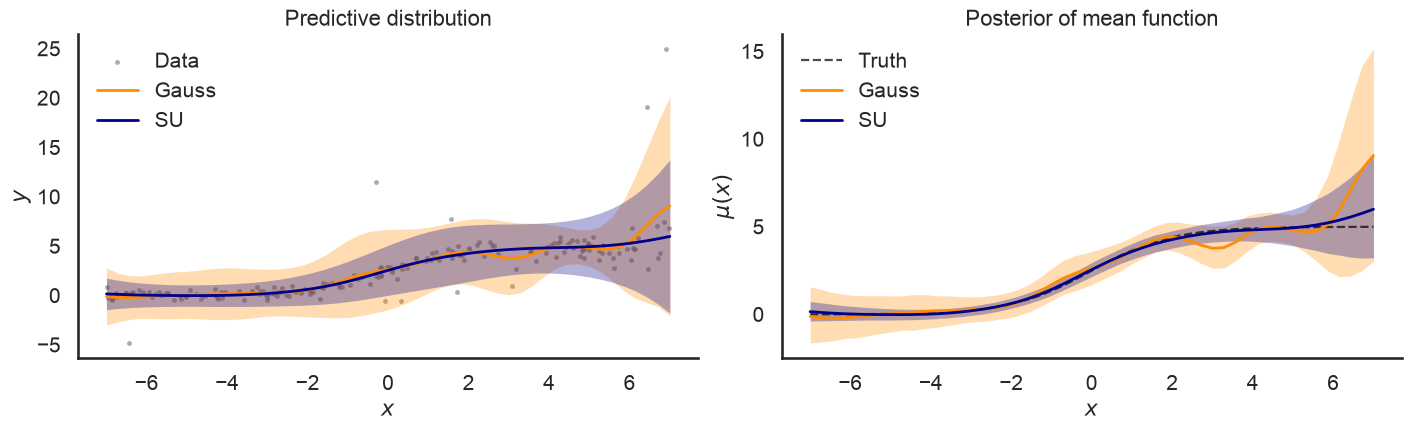

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from simulation.sim_utils import MSE, coverage, interval_length, mean_test_logpdf


# ============================================================
# PERFORMANCE METRICS
# ============================================================

metric_rows = []

for method in methods:
    specification = METHODS[method]
    moments = results[method]["moments"]
    model = results[method]["model"]

    metric_rows.append(
        {
            "Method": specification["label"],

            # ------------------------------------------------
            # Test log predictive density
            # ------------------------------------------------
            "Test log likelihood": mean_test_logpdf(
                model,
                X_test,
                y_test,
            ),

            # ------------------------------------------------
            # Mean function
            # ------------------------------------------------
            "Mean MSE": MSE(
                moments,
                "μ",
                mean_truth,
            ),

            "Mean coverage": coverage(
                moments,
                "μ",
                mean_truth,
            ),

            "Mean interval length": interval_length(
                moments,
                "μ",
            ),

            # ------------------------------------------------
            # Variance function
            # ------------------------------------------------
            "Variance MSE": MSE(
                moments,
                "σ2",
                var_truth,
            ),

            "Variance coverage": coverage(
                moments,
                "σ2",
                var_truth,
            ),

            "Variance interval length": interval_length(
                moments,
                "σ2",
            ),
        }
    )


metrics_df = pd.DataFrame(metric_rows)


# ============================================================
# PRINT PERFORMANCE METRICS
# ============================================================

print("\nPerformance metrics")
print("=" * 140)

print(
    metrics_df.to_string(
        index=False,
        formatters={
            "Test log likelihood": "{:.4f}".format,
            "Mean MSE": "{:.4f}".format,
            "Mean coverage": "{:.3f}".format,
            "Mean interval length": "{:.4f}".format,
            "Variance MSE": "{:.4f}".format,
            "Variance coverage": "{:.3f}".format,
            "Variance interval length": "{:.4f}".format,
        },
    )
)


# ============================================================
# SEABORN STYLE
# ============================================================

sns.set_theme(
    style="white",
    context="talk",
    font_scale=0.9,
)


# ============================================================
# TWO-PANEL PLOT
# ============================================================

x_grid = np.asarray(x_plot[:, 0])
order = np.argsort(x_grid)

x_grid = x_grid[order]
mean_truth_plot = np.asarray(mean_truth)[order]
var_truth_plot = np.asarray(var_truth)[order]


fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 4.2),
    constrained_layout=True,
)


# ============================================================
# Panel 1: data and predictive intervals
# ============================================================

sns.scatterplot(
    x=X[:, 0],
    y=y,
    s=10,
    color="gray",
    alpha=0.65,
    edgecolor=None,
    label="Data",
    ax=axes[0],
    zorder=1,
)


for method in methods:
    specification = METHODS[method]
    prediction = results[method]["prediction"]

    predictive_mean = np.asarray(prediction["μ"])[order]
    predictive_lower = np.asarray(prediction["y_l"])[order]
    predictive_upper = np.asarray(prediction["y_h"])[order]

    sns.lineplot(
        x=x_grid,
        y=predictive_mean,
        color=specification["color"],
        linewidth=2,
        label=specification["label"],
        ax=axes[0],
        zorder=3,
    )

    axes[0].fill_between(
        x_grid,
        predictive_lower,
        predictive_upper,
        color=specification["color"],
        alpha=0.30,
        linewidth=0,
        zorder=2,
    )


axes[0].set(
    title="Predictive distribution",
    xlabel=r"$x$",
    ylabel=r"$y$",
)

if y_range is not None:
    axes[0].set_ylim(y_range)

axes[0].legend(frameon=False)


# ============================================================
# Panel 2: posterior mean function
# ============================================================

sns.lineplot(
    x=x_grid,
    y=mean_truth_plot,
    linestyle="--",
    color="black",
    linewidth=1.6,
    alpha=0.7,
    label="Truth",
    ax=axes[1],
)


for method in methods:
    specification = METHODS[method]
    moments = results[method]["moments"]

    posterior_mean = np.asarray(moments["μ_mean"])[order]
    credible_lower = np.asarray(moments["μ_l"])[order]
    credible_upper = np.asarray(moments["μ_h"])[order]

    sns.lineplot(
        x=x_grid,
        y=posterior_mean,
        color=specification["color"],
        linewidth=2,
        label=specification["label"],
        ax=axes[1],
    )

    axes[1].fill_between(
        x_grid,
        credible_lower,
        credible_upper,
        color=specification["color"],
        alpha=0.30,
        linewidth=0,
    )


axes[1].set(
    title="Posterior of mean function",
    xlabel=r"$x$",
    ylabel=r"$\mu(x)$",
)

if y_range is not None:
    axes[1].set_ylim(y_range)

axes[1].legend(frameon=False)


# ============================================================
# Final styling
# ============================================================

sns.despine(fig=fig)

# Explicitly ensure there are no background grid lines
for ax in axes:
    ax.grid(False, which="both", axis="both")


plt.savefig(
    "./plots/simulation/kurt_sim.pdf",
    bbox_inches="tight",
)

plt.show()

# Multi-output Example 3.1

Uses the saved two-output heteroscedastic data with `n=200`, `B=1000`, `T=4000`.


In [5]:
from recursive_moments import RMMOGauss
from simulation.sim_utils import time_call

X = np.loadtxt("data/simulation/sim_mohet_X_seed125_n200.csv", delimiter=",").reshape(-1, 1)
y = np.loadtxt("data/simulation/sim_mohet_y_seed125_n200.csv", delimiter=",")
x_plot = np.loadtxt("data/simulation/sim_mohet_x_grid.csv", delimiter=",").reshape(-1, 1)
model_mohet = RMMOGauss(optimize=True, n_perm_opt=10, n_perm_fit=10)
_, fit_seconds = time_call(lambda: model_mohet.fit(X, y))
pred_mohet, predict_seconds = time_call(lambda: model_mohet.predict(x_plot))
(_, moments_mohet), pr_seconds = time_call(lambda: model_mohet.pr(
    X_test=x_plot, T=4000, B=1000, seed=126,
    return_intervals=True, X_range=(np.array([-7.]), np.array([7.])),
))
print(f"Fit: {fit_seconds:.3f}s; prediction: {predict_seconds:.3f}s; "
      f"PR: {pr_seconds:.3f}s; total: {fit_seconds + predict_seconds + pr_seconds:.3f}s")


Bandwidth optimization success: True
Fit: 0.699s; prediction: 0.002s; PR: 0.356s; total: 1.057s
